# Homework Assignement #3

## Apply a Logistic Regression model

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

### Sigmoid

$\sigma( w^T x + b) = \dfrac{1}{1 + e^{-(w^T x + b)}}$

In [2]:
# sigmoid

def sigmoid(z):
    """
    Compute the sigmoid of z

    Arguments:
    z -- A scalar or numpy array of any size.

    Return:
    s -- sigmoid(z)
    """
    s = 1. /(1. + np.exp(-z))

    return s

In [3]:
# initialize_with_zeros

def initialize_with_zeros(dim):
    """
    This function creates a vector of zeros of shape (dim, 1) for w and initializes b to 0.

    Argument:
    dim -- size of the w vector we want (or number of parameters in this case)

    Returns:
    w -- initialized vector of shape (dim, 1)
    b -- initialized scalar (corresponds to the bias)
    """
    #w = np.ones((dim,1))
    w = np.random.normal(loc=0.0, scale=1.0, size=dim).reshape(dim,1)
    b = 0.

    return w, b

In [4]:
# propagate

def propagate(w, b, X, Y):
    """
    Implement the cost function and its gradient for the propagation explained above

    Arguments:
    w -- weights, a numpy array of size which equals the number of features
    b -- bias, a scalar
    X -- data
    Y -- true "label" vector (containing 0 and 1) of size (1, number of examples)

    Return:
    cost -- negative log-likelihood cost for logistic regression
    dw -- gradient of the loss with respect to w, thus same shape as w
    db -- gradient of the loss with respect to b, thus same shape as b

    """
    m = X.shape[1]
    #print('number of objects = ',len(X))

    # FORWARD PROPAGATION (FROM X TO COST)
    A = sigmoid(np.dot(w.T,X)+b )                                 # compute activation
    cost = -(1./m)*np.sum(Y*np.log(A)+(1-Y)*np.log(1-A),axis=1)   # compute cost

    # BACKWARD PROPAGATION (TO FIND GRAD)
    dw = (1./m)*np.dot(X,(A-Y).T)
    db = (1./m)*np.sum(A-Y,axis=1)

    grads = {"dw": dw,
             "db": db}

    return grads, cost

In [5]:
# predict

def predict(w, b, X, threshold=0.5):
    '''
    Predict whether the label is 0 or 1 using learned logistic regression parameters (w, b)

    Arguments:
    w -- weights, a numpy array
    b -- bias, a scalar
    X -- data

    Returns:
    Y_prediction -- a numpy array (vector) containing all predictions (0/1) for the examples in X
    '''

    m = X.shape[1] # - number of objects
    Y_prediction = np.zeros((1,m))
    w = w.reshape(X.shape[0], 1) # X.shape[0] - number of features

    # Compute vector "A" predicting the probabilities
    A = sigmoid(np.dot(w.T,X)+b)

    for i in range(A.shape[1]):

        # Convert probabilities A[0,i] to actual predictions p[0,i]
        if (A[0,i]<=threshold):
            Y_prediction[0][i]=0
        else:
            Y_prediction[0][i]=1

    return Y_prediction

### Data preparation

In [6]:
df = pd.read_csv('bioresponse.csv')

In [7]:
df

,Activity,D1,D2,D3,D4,D5,D6,D7,D8,D9,...,D1767,D1768,D1769,D1770,D1771,D1772,D1773,D1774,D1775,D1776
0,1,0.000000,0.497009,0.10,0.0,0.132956,0.678031,0.273166,0.585445,0.743663,...,0,0,0,0,0,0,0,0,0,0
1,1,0.366667,0.606291,0.05,0.0,0.111209,0.803455,0.106105,0.411754,0.836582,...,1,1,1,1,0,1,0,0,1,0
2,1,0.033300,0.480124,0.00,0.0,0.209791,0.610350,0.356453,0.517720,0.679051,...,0,0,0,0,0,0,0,0,0,0
3,1,0.000000,0.538825,0.00,0.5,0.196344,0.724230,0.235606,0.288764,0.805110,...,0,0,0,0,0,0,0,0,0,0
4,0,0.100000,0.517794,0.00,0.0,0.494734,0.781422,0.154361,0.303809,0.812646,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3746,1,0.033300,0.506409,0.10,0.0,0.209887,0.633426,0.297659,0.376124,0.727093,...,0,0,0,0,0,0,0,0,0,0
3747,1,0.133333,0.651023,0.15,0.0,0.151154,0.766505,0.170876,0.404546,0.787935,...,0,0,1,0,1,0,1,0,0,0
3748,0,0.200000,0.520564,0.00,0.0,0.179949,0.768785,0.177341,0.471179,0.872241,...,0,0,0,0,0,0,0,0,0,0
3749,1,0.100000,0.765646,0.00,0.0,0.536954,0.634936,0.342713,0.447162,0.672689,...,0,0,0,0,0,0,0,0,0,0


In [8]:
y = df.iloc[:, 0].values            # labels (0/1)
X = df.iloc[:, 1:].values           # 1776 descriptors

In [9]:
y

array([1, 1, 1, ..., 0, 1, 0], shape=(3751,))

In [10]:
X

array([[0.        , 0.49700901, 0.1       , ..., 0.        , 0.        ,
        0.        ],
       [0.36666667, 0.60629148, 0.05      , ..., 0.        , 1.        ,
        0.        ],
       [0.0333    , 0.48012427, 0.        , ..., 0.        , 0.        ,
        0.        ],
       ...,
       [0.2       , 0.52056377, 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.1       , 0.7656462 , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.13333333, 0.53395198, 0.        , ..., 0.        , 0.        ,
        0.        ]], shape=(3751, 1776))

In [11]:
X_train, X_test, y_train, y_test = train_test_split(     
    X, y, test_size=0.25, random_state=42, stratify=y) 

In [12]:
# Transpose to the shape the notebook "Logistic..." uses: (n_features, m)
X_train, X_test = X_train.T, X_test.T
Y_train = y_train.reshape(1, -1)
Y_test  = y_test.reshape(1, -1)

In [13]:
X_train

array([[0.2       , 0.26666667, 0.        , ..., 0.        , 0.1       ,
        0.13333333],
       [0.68636454, 0.58574476, 0.44929326, ..., 0.37564861, 0.63257138,
        0.67333243],
       [0.2       , 0.1       , 0.        , ..., 0.        , 0.15      ,
        0.1       ],
       ...,
       [0.        , 1.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 1.        , 0.        , ..., 0.        , 0.        ,
        0.        ]], shape=(1776, 2813))

In [14]:
Y_train

array([[0, 0, 1, ..., 1, 0, 1]], shape=(1, 2813))

In [15]:
def accuracy(Y_pred, Y_true):
    return np.mean(Y_pred == Y_true) * 100

 Modify optimize() function to implement the stochastic gradient descent (SGD) method.

In [16]:
# optimize

def optimize(w, b, X, Y, num_iterations, learning_rate, print_cost = False):
    """
    This function optimizes w and b by running a gradient descent algorithm

    Arguments:
    w -- weights, a numpy array
    b -- bias, a scalar
    X -- data
    Y -- true "label" vector (containing 0 and 1), of shape (1, number of examples)
    num_iterations -- number of iterations of the optimization loop
    learning_rate -- learning rate of the gradient descent update rule
    print_cost -- True to print the loss every 100 steps

    Returns:
    params -- dictionary containing the weights w and bias b
    grads -- dictionary containing the gradients of the weights and bias with respect to the cost function
    costs -- list of all the costs computed during the optimization, this will be used to plot the learning curve.

    """

    costs = []

    for i in range(num_iterations):

        # Cost and gradient calculation
        grads, cost = propagate(w,b,X,Y)

        # Retrieve derivatives from grads
        dw = grads["dw"]
        db = grads["db"]

        # update rule
        w -=learning_rate * dw
        b -=learning_rate * db

        # Record full-batch cost every epoch
        c = cost.item()
        costs.append(c)

        # Print the cost every 100 training iterations
        if print_cost and i // 100 == 0:
            print (f"Cost after iteration {i}: {round(cost[0], 7)}")

    params = {"w": w,
              "b": b}

    grads = {"dw": dw,
             "db": db}

    return params, grads, costs 

Stochastic Gradient Descent (SGD)

In [17]:
def optimize_sgd(w, b, X, Y, num_epochs, learning_rate, batch_size=1, print_cost=False):

    costs = []
    m = X.shape[1]
    
    for epoch in range(num_epochs):
        perm = np.random.permutation(m)
        Xs, Ys = X[:, perm], Y[:, perm]
        
        for start in range(0, m, batch_size):
            Xb = Xs[:, start:start + batch_size]
            Yb = Ys[:, start:start + batch_size]
            grads, _ = propagate(w, b, Xb, Yb) # Ignore mini-batch cost
            w -= learning_rate * grads["dw"]
            b -= learning_rate * grads["db"]
            
        # Record full-batch cost at the end of the epoch
        _, full_cost = propagate(w, b, X, Y)
        c = full_cost.item()
        costs.append(c)
        
        if print_cost and epoch % 10 == 0:
            print(f"SGD  epoch {epoch:3d}  loss = {c:.5f}")

    params = {"w": w,
              "b": b}
            
    return params, grads, costs

Implement the Adam optimization method using the numpy library and compare the accuracy of the model fitted with it with the models trained by the classic GD (p.1) and SGD (p2) algorithms.

https://github.com/theroyakash/Adam - here is the notebook with Adam implementation.


In [18]:
def optimize_adam(w, b, X, Y, num_iterations, learning_rate,
                  beta1=0.9, beta2=0.999, epsilon=1e-8, print_cost=False):
    costs = []
    v_dw = np.zeros_like(w); v_db = 0.
    s_dw = np.zeros_like(w); s_db = 0.

    for t in range(num_iterations):
        grads, cost = propagate(w, b, X, Y)
        dw, db = grads["dw"], grads["db"]

        # biased first moment estimate
        v_dw = beta1 * v_dw + (1 - beta1) * dw
        v_db = beta1 * v_db + (1 - beta1) * db

        # biased second raw moment estimate
        s_dw = beta2 * s_dw + (1 - beta2) * dw ** 2
        s_db = beta2 * s_db + (1 - beta2) * db ** 2

        # bias correction
        v_dw_hat = v_dw / (1 - beta1 ** (t + 1))
        v_db_hat = v_db / (1 - beta1 ** (t + 1))
        s_dw_hat = s_dw / (1 - beta2 ** (t + 1))
        s_db_hat = s_db / (1 - beta2 ** (t + 1))

        # parameter update
        w -= learning_rate * v_dw_hat / (np.sqrt(s_dw_hat) + epsilon)
        b -= learning_rate * v_db_hat / (np.sqrt(s_db_hat) + epsilon)

        # Append cost every epoch
        costs.append(cost)

        if print_cost and t % 10 == 0:
            print(f"Adam iter {t:5d}  loss = {cost.item():.5f}")

    params = {"w": w, "b": b}

    grads = {"dw": dw, "db": db}

    return params, grads, costs

Train all three models and compare accuracy

In [19]:
np.random.seed(2026)

In [20]:
w0, b0 = initialize_with_zeros(X_train.shape[0])
w0 = w0 * 0.01          # numerical stability for high-dimensional input

In [21]:
EPOCHS = 100

In [22]:
# GD
p_gd, _, c_gd = optimize(w0.copy(), b0, X_train, Y_train, 
                            num_iterations=EPOCHS, learning_rate=0.1, print_cost=True)

Cost after iteration 0: 0.7035124
Cost after iteration 1: 0.6836547
Cost after iteration 2: 0.6738659
Cost after iteration 3: 0.6665788
Cost after iteration 4: 0.6601087
Cost after iteration 5: 0.6541485
Cost after iteration 6: 0.6485983
Cost after iteration 7: 0.6434044
Cost after iteration 8: 0.6385269
Cost after iteration 9: 0.6339333
Cost after iteration 10: 0.6295957
Cost after iteration 11: 0.6254902
Cost after iteration 12: 0.6215958
Cost after iteration 13: 0.6178942
Cost after iteration 14: 0.6143692
Cost after iteration 15: 0.6110064
Cost after iteration 16: 0.6077928
Cost after iteration 17: 0.6047171
Cost after iteration 18: 0.6017689
Cost after iteration 19: 0.5989389
Cost after iteration 20: 0.5962187
Cost after iteration 21: 0.5936008
Cost after iteration 22: 0.5910783
Cost after iteration 23: 0.588645
Cost after iteration 24: 0.5862952
Cost after iteration 25: 0.5840238
Cost after iteration 26: 0.581826
Cost after iteration 27: 0.5796974
Cost after iteration 28: 0.57763

In [23]:
# SGD
p_sgd, _, c_sgd = optimize_sgd(w0.copy(), b0, X_train, Y_train, 
                               num_epochs=EPOCHS, learning_rate=0.01, batch_size=1, print_cost=True)

SGD  epoch   0  loss = 0.56072
SGD  epoch  10  loss = 0.36564
SGD  epoch  20  loss = 0.33376
SGD  epoch  30  loss = 0.32226
SGD  epoch  40  loss = 0.31255
SGD  epoch  50  loss = 0.31305
SGD  epoch  60  loss = 0.29822
SGD  epoch  70  loss = 0.29096
SGD  epoch  80  loss = 0.28494
SGD  epoch  90  loss = 0.27965


In [24]:
# Adam
p_adam, _, c_adam = optimize_adam(w0.copy(), b0, X_train, Y_train, 
                                  num_iterations=EPOCHS, learning_rate=0.01, print_cost=True)

Adam iter     0  loss = 0.70351
Adam iter    10  loss = 0.57547
Adam iter    20  loss = 0.51313
Adam iter    30  loss = 0.47509
Adam iter    40  loss = 0.44852
Adam iter    50  loss = 0.42913
Adam iter    60  loss = 0.41413
Adam iter    70  loss = 0.40189
Adam iter    80  loss = 0.39154
Adam iter    90  loss = 0.38254


In [25]:
# Test accuracy 
acc_gd   = accuracy(predict(p_gd["w"],   p_gd["b"],   X_test), Y_test)
acc_sgd  = accuracy(predict(p_sgd["w"],  p_sgd["b"],  X_test), Y_test)
acc_adam = accuracy(predict(p_adam["w"], p_adam["b"], X_test), Y_test)

In [26]:
print("Test Accuracy")
print(f"GD    : {acc_gd:6.2f} %")
print(f"SGD   : {acc_sgd:6.2f} %")
print(f"Adam  : {acc_adam:6.2f} %")

Test Accuracy
GD    :  72.49 %
SGD   :  74.31 %
Adam  :  76.12 %


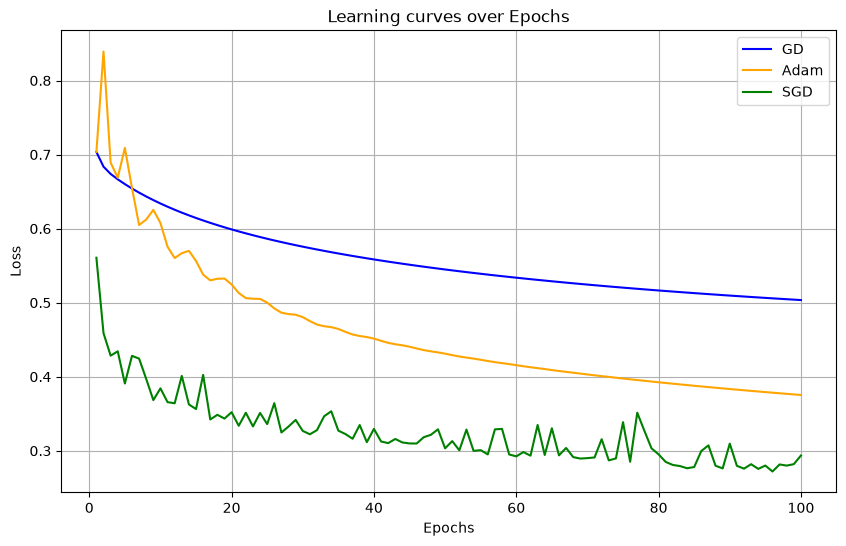

In [27]:
# Plot
plt.figure(figsize=(10, 6))
epochs_range = np.arange(1, EPOCHS + 1)

plt.plot(epochs_range, c_gd,   label='GD', color='blue')
plt.plot(epochs_range, c_adam, label='Adam', color='orange')
plt.plot(epochs_range, c_sgd,  label='SGD', color='green')

plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Learning curves over Epochs')
plt.legend()
plt.grid(True)
plt.show()

Train the models with different values of the learning rate (at least 5 different values of learning rate). Plot the learning curves for all these cases.

In [28]:
# Define 5 learning rates for each optimizer
lrs_gd   = [0.01, 0.05, 0.1, 0.5, 1.0]
lrs_sgd  = [0.0001, 0.001, 0.005, 0.01, 0.02]
lrs_adam = [0.0001, 0.001, 0.005, 0.01, 0.05]

In [29]:
# Dictionaries to store results for plotting
results_gd, results_sgd, results_adam = {}, {}, {}

In [30]:
# GD 
for lr in lrs_gd:
    p, _, c = optimize(w0.copy(), b0, X_train, Y_train, num_iterations=EPOCHS, learning_rate=lr)
    acc = accuracy(predict(p["w"], p["b"], X_test), Y_test)
    results_gd[lr] = (c, acc)

C:\Users\Павел\AppData\Local\Temp\ipykernel_19188\3354999311.py:24: RuntimeWarning: divide by zero encountered in log
  cost = -(1./m)*np.sum(Y*np.log(A)+(1-Y)*np.log(1-A),axis=1)   # compute cost
C:\Users\Павел\AppData\Local\Temp\ipykernel_19188\3354999311.py:24: RuntimeWarning: invalid value encountered in multiply
  cost = -(1./m)*np.sum(Y*np.log(A)+(1-Y)*np.log(1-A),axis=1)   # compute cost


In [31]:
# SGD 
for lr in lrs_sgd:
    p, _, c = optimize_sgd(w0.copy(), b0, X_train, Y_train, num_epochs=EPOCHS, learning_rate=lr, batch_size=1)
    acc = accuracy(predict(p["w"], p["b"], X_test), Y_test)
    results_sgd[lr] = (c, acc)

In [32]:
# Adam 
for lr in lrs_adam:
    p, _, c = optimize_adam(w0.copy(), b0, X_train, Y_train, num_iterations=EPOCHS, learning_rate=lr)
    acc = accuracy(predict(p["w"], p["b"], X_test), Y_test)
    results_adam[lr] = (c, acc)

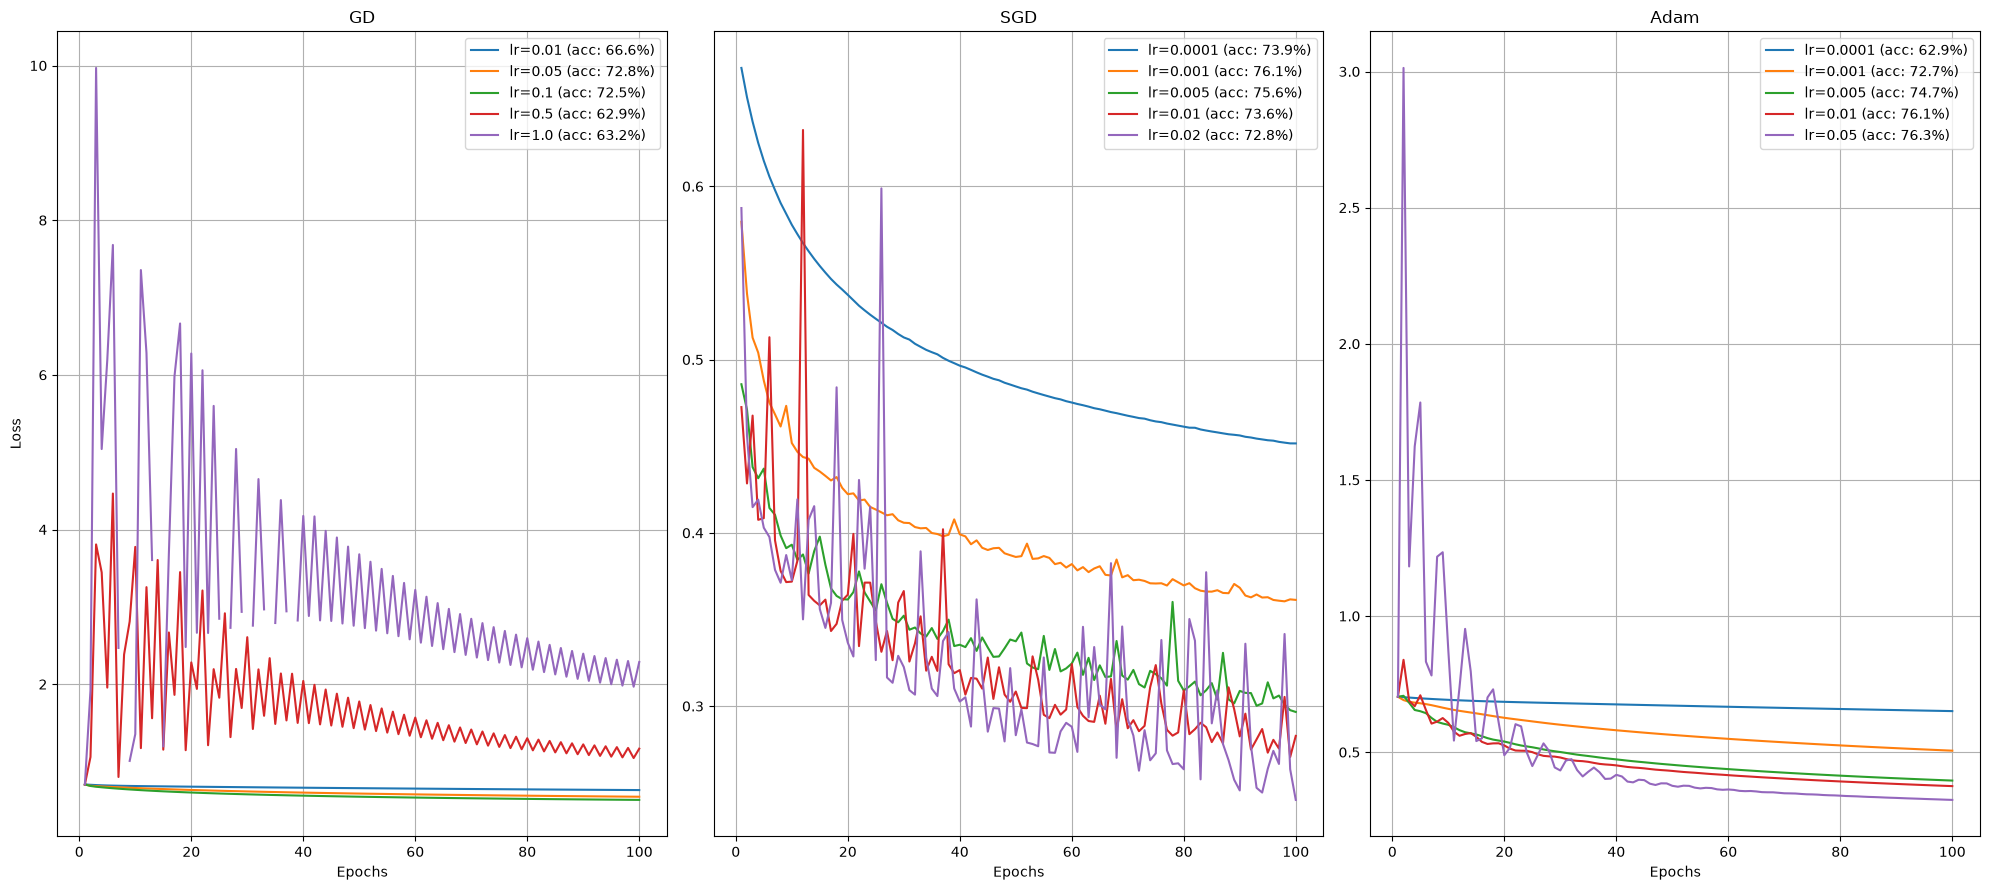

In [33]:
# Plot
fig, axes = plt.subplots(1, 3, figsize=(20, 9))
epochs_range = np.arange(1, EPOCHS + 1)

# Plot GD
for lr, (costs, acc) in results_gd.items():
    axes[0].plot(epochs_range, costs, label=f"lr={lr} (acc: {acc:.1f}%)")
axes[0].set_title("GD")
axes[0].set_xlabel("Epochs"); axes[0].set_ylabel("Loss")
axes[0].legend(); axes[0].grid(True)

# Plot SGD
for lr, (costs, acc) in results_sgd.items():
    axes[1].plot(epochs_range, costs, label=f"lr={lr} (acc: {acc:.1f}%)")
axes[1].set_title("SGD")
axes[1].set_xlabel("Epochs")
axes[1].legend(); axes[1].grid(True)

# Plot Adam
for lr, (costs, acc) in results_adam.items():
    axes[2].plot(epochs_range, costs, label=f"lr={lr} (acc: {acc:.1f}%)")
axes[2].set_title("Adam")
axes[2].set_xlabel("Epochs")
axes[2].legend(); axes[2].grid(True)

plt.tight_layout()
plt.show()

## Conclusion

 Adam achieved the highest test accuracy (76.12%) due to its adaptive per-feature learning rate, while SGD slightly overfit the data, and GD was the most stable but slowest. Testing five different learning rates proved that this hyperparameter is critical: rates too small caused slow convergence (underfitting), while rates too high caused the sigmoid function to saturate, resulting in `NaN` losses and model divergence. **Adam proved to be the most robust and efficient optimization method**.